# Estimating Lifecycle Carbon Intensity from ENTSO-E Generation Data

This notebook reproduces the DE-LU generation-weighted lifecycle carbon-intensity estimate from the input CSV.

**Method:** for each 15-minute interval, calculate the generation-weighted average of assigned lifecycle emission factors:

\[
CI_t = \frac{\sum_i P_{i,t} EF_i}{\sum_i P_{i,t}}
\]

where `P` is generation in MW and `EF` is the assumed lifecycle factor in gCO₂eq/kWh. The interval's estimated energy is `MW × 0.25 h`. Estimated emissions in tonnes CO₂eq are `MW × 0.25 × EF / 1000`.

The factors are configurable assumptions, not official real-time grid-intensity values. Storage is excluded because its emissions depend on the charging electricity and its accounting boundary.

## 1. Install and import dependencies
Run the installation cell only if the packages are not already installed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 3.0.6
numpy: 2.5.4


## 2. Configure input/output paths

Place the source CSV in the same directory as this notebook, or change `INPUT_CSV` to its full path. The output CSV is written to `OUTPUT_CSV`.

In [2]:
INPUT_CSV = Path("data/PL_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv")
OUTPUT_CSV = Path("data/PL_generation_with_estimated_carbon_intensity.csv")

# The source data uses 15-minute intervals.
INTERVAL_HOURS = 0.25

if not INPUT_CSV.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_CSV.resolve()}\n"
        "Put the CSV beside the notebook or update INPUT_CSV."
    )

print("Input:", INPUT_CSV.resolve())
print("Output:", OUTPUT_CSV.resolve())

Input: C:\University25\master\_teza_master\soft\project\data\PL_AGGREGATED_GENERATION_PER_TYPE_GENERATION.csv
Output: C:\University25\master\_teza_master\soft\project\data\PL_generation_with_estimated_carbon_intensity.csv


## 3. Load and inspect the source data

In [3]:
df = pd.read_csv(INPUT_CSV, dtype={"Generation (MW)": "string"})

required_columns = {"MTU (CET/CEST)", "Area", "Production Type", "Generation (MW)"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())
display(df["Production Type"].value_counts(dropna=False).rename("row_count").to_frame())
display(df["Generation (MW)"].value_counts(dropna=False).head(10).rename("count").to_frame())

Rows: 735840
Columns: ['MTU (CET/CEST)', 'Area', 'Production Type', 'Generation (MW)']


,MTU (CET/CEST),Area,Production Type,Generation (MW)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|PL,Biomass,368.28
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|PL,Biomass,376.18
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|PL,Biomass,379.39
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|PL,Biomass,377.89
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|PL,Biomass,377.93


,row_count
Production Type,
Biomass,35040
Energy storage,35040
Fossil Brown coal/Lignite,35040
Fossil Coal-derived gas,35040
Fossil Gas,35040
Fossil Hard coal,35040
Fossil Oil,35040
Fossil Oil shale,35040
Fossil Peat,35040


,count
Generation (MW),
n/e,252952
-,118650
0.00,33673
53.00,68
122.80,66
78.10,58
76.60,57
11.04,52
77.50,51


## 4. Define lifecycle emission factors

The following mapping reproduces the assumptions used in the enriched CSV. Factors for additional ENTSO-E categories are proxies and should be justified or replaced with source-specific literature values in the final thesis.

In [4]:
EMISSION_FACTORS = {
    # Factors supplied in the question or mapped directly to those categories
    "Wind Onshore": 11.0,
    "Wind Offshore": 11.0,
    "Solar": 48.0,
    "Nuclear": 12.0,
    "Hydro Run-of-river and pondage": 24.0,
    "Hydro Water Reservoir": 24.0,
    "Biomass": 230.0,
    "Fossil Gas": 490.0,
    "Fossil Coal-derived gas": 490.0,
    "Fossil Brown coal/Lignite": 820.0,
    "Fossil Hard coal": 820.0,
    "Fossil Oil": 650.0,
    "Fossil Oil shale": 650.0,
    "Fossil Peat": 820.0,
    "Geothermal": 24.0,          # hydro proxy
    "Marine": 24.0,              # hydro proxy
    "Other renewable": 48.0,     # solar proxy
    "Other": 490.0,              # gas proxy
    "Waste": 500.0,              # approximate proxy; highly technology-dependent
}

# Deliberately excluded from the intensity denominator.
# Energy storage and pumped hydro require charging-energy attribution to avoid
# treating stored electricity as an independent primary generation source.
EXCLUDED_SOURCES = {
    "Energy storage",
    "Hydro Pumped Storage",
}

factor_table = (
    pd.DataFrame(
        [{"Production Type": source, "Lifecycle emission factor (gCO2eq/kWh)": factor}
         for source, factor in EMISSION_FACTORS.items()]
    )
    .sort_values("Production Type")
    .reset_index(drop=True)
)
display(factor_table)

print("Sources in input without a factor:")
print(sorted(set(df["Production Type"].dropna().unique()) - set(EMISSION_FACTORS) - EXCLUDED_SOURCES))

print("Excluded sources present in input:")
print(sorted(set(df["Production Type"].dropna().unique()) & EXCLUDED_SOURCES))

,Production Type,Lifecycle emission factor (gCO2eq/kWh)
0,Biomass,230.0
1,Fossil Brown coal/Lignite,820.0
2,Fossil Coal-derived gas,490.0
3,Fossil Gas,490.0
4,Fossil Hard coal,820.0
5,Fossil Oil,650.0
6,Fossil Oil shale,650.0
7,Fossil Peat,820.0
8,Geothermal,24.0
9,Hydro Run-of-river and pondage,24.0


Sources in input without a factor:
[]
Excluded sources present in input:
['Energy storage', 'Hydro Pumped Storage']


## 5. Clean generation values and parse interval timestamps

ENTSO-E exports may use `n/e`, `-`, or blanks for unavailable values. These are converted to `NaN`, not zero. Interval start and end times are extracted from the `MTU (CET/CEST)` text. The timestamps are kept as local, timezone-naive timestamps because the source string mixes CET/CEST notation; local-time interpretation around daylight-saving transitions should be checked if exact UTC alignment is required.

In [5]:
work = df.copy()

# Convert generation to numeric. Invalid tokens such as "n/e" and "-" become NaN.
work["Generation (MW)"] = pd.to_numeric(
    work["Generation (MW)"].astype("string").str.strip().replace({"": pd.NA, "n/e": pd.NA, "-": pd.NA}),
    errors="coerce"
)

# Split the interval string into start and end timestamps.
interval_parts = work["MTU (CET/CEST)"].astype("string").str.split(r"\s+-\s+", n=1, expand=True)
if interval_parts.shape[1] != 2:
    raise ValueError("Could not parse interval column; expected 'start - end' strings.")

work["Interval start"] = pd.to_datetime(interval_parts[0], dayfirst=True, errors="coerce")
work["Interval end"] = pd.to_datetime(interval_parts[1], dayfirst=True, errors="coerce")

work["Lifecycle emission factor (gCO2eq/kWh)"] = work["Production Type"].map(EMISSION_FACTORS)

# Exclude storage and any un-mapped source from the calculation.
work["Included in carbon-intensity calculation"] = (
    work["Lifecycle emission factor (gCO2eq/kWh)"].notna()
    & work["Generation (MW)"].notna()
)

print("Rows:", len(work))
print("Invalid/missing generation values:", int(work["Generation (MW)"].isna().sum()))
print("Unparsed interval starts:", int(work["Interval start"].isna().sum()))
print("Rows excluded due to missing factor or generation:",
      int((~work["Included in carbon-intensity calculation"]).sum()))
display(work.head())

Rows: 735840
Invalid/missing generation values: 371602
Unparsed interval starts: 210
Rows excluded due to missing factor or generation: 401002


,MTU (CET/CEST),Area,Production Type,Generation (MW),Interval start,Interval end,Lifecycle emission factor (gCO2eq/kWh),Included in carbon-intensity calculation
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|PL,Biomass,368.28,2026-01-01 00:00:00,2026-01-01 00:15:00,230.0,True
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|PL,Biomass,376.18,2026-01-01 00:15:00,2026-01-01 00:30:00,230.0,True
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|PL,Biomass,379.39,2026-01-01 00:30:00,2026-01-01 00:45:00,230.0,True
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|PL,Biomass,377.89,2026-01-01 00:45:00,2026-01-01 01:00:00,230.0,True
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|PL,Biomass,377.93,2026-01-01 01:00:00,2026-01-01 01:15:00,230.0,True


## 6. Calculate emissions per source row

In [6]:
# Generation (MW) is treated as average power over the interval.
# Energy (MWh) = power (MW) × interval duration (hours).
work["Generation included (MW)"] = work["Generation (MW)"].where(
    work["Included in carbon-intensity calculation"], 0.0
)

# For a 15-minute interval:
# tCO2eq = MW × 0.25 h × 1000 kWh/MWh × EF g/kWh / 1,000,000 g/t
#        = MW × 0.25 × EF / 1000
work["Estimated emissions (tCO2eq per 15 min)"] = (
    work["Generation (MW)"]
    * INTERVAL_HOURS
    * work["Lifecycle emission factor (gCO2eq/kWh)"]
    / 1000.0
)

# Set emissions to NaN where the source is excluded or generation is unavailable.
work.loc[~work["Included in carbon-intensity calculation"],
         "Estimated emissions (tCO2eq per 15 min)"] = np.nan

display(work[[
    "MTU (CET/CEST)", "Production Type", "Generation (MW)",
    "Lifecycle emission factor (gCO2eq/kWh)",
    "Estimated emissions (tCO2eq per 15 min)"
]].head(10))

,MTU (CET/CEST),Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,Biomass,368.28,230.0,21.1761
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,Biomass,376.18,230.0,21.63035
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,Biomass,379.39,230.0,21.814925
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,Biomass,377.89,230.0,21.728675
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,Biomass,377.93,230.0,21.730975
5,01/01/2026 01:15:00 - 01/01/2026 01:30:00,Biomass,377.41,230.0,21.701075
6,01/01/2026 01:30:00 - 01/01/2026 01:45:00,Biomass,376.91,230.0,21.672325
7,01/01/2026 01:45:00 - 01/01/2026 02:00:00,Biomass,376.65,230.0,21.657375
8,01/01/2026 02:00:00 - 01/01/2026 02:15:00,Biomass,374.87,230.0,21.555025
9,01/01/2026 02:15:00 - 01/01/2026 02:30:00,Biomass,377.31,230.0,21.695325


## 7. Aggregate generation and emissions by interval

Carbon intensity is calculated from the sum of generation-weighted factors divided by included generation. The resulting interval-level metrics are then joined back to every production-type row, so each row for a given interval carries the same grid-mix estimate.

In [7]:
GROUP_KEYS = ["MTU (CET/CEST)", "Area"]

# Calculate the weighted numerator only for included sources with valid generation.
work["Weighted generation × factor"] = (
    work["Generation included (MW)"]
    * work["Lifecycle emission factor (gCO2eq/kWh)"].fillna(0.0)
)

interval_summary = (
    work.groupby(GROUP_KEYS, dropna=False)
    .agg(
        **{
            "Total generation included (MW)": ("Generation included (MW)", "sum"),
            "Weighted generation × factor": ("Weighted generation × factor", "sum"),
            "Estimated total emissions (tCO2eq per 15 min)": (
                "Estimated emissions (tCO2eq per 15 min)",
                lambda s: s.sum(min_count=1)
            ),
            "Interval start": ("Interval start", "min"),
            "Interval end": ("Interval end", "max"),
        }
    )
    .reset_index()
)

interval_summary["Estimated carbon intensity (gCO2eq/kWh)"] = np.where(
    interval_summary["Total generation included (MW)"] > 0,
    interval_summary["Weighted generation × factor"]
        / interval_summary["Total generation included (MW)"],
    np.nan
)

# Remove the internal numerator from the published interval summary.
interval_summary = interval_summary.drop(columns=["Weighted generation × factor"])

display(interval_summary.head())
print("Intervals:", len(interval_summary))
print("Intervals with no included generation:",
      int(interval_summary["Estimated carbon intensity (gCO2eq/kWh)"].isna().sum()))

,MTU (CET/CEST),Area,Total generation included (MW),Estimated total emissions (tCO2eq per 15 min),Interval start,Interval end,Estimated carbon intensity (gCO2eq/kWh)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|PL,15286.95,2394.656888,2026-01-01 00:00:00,2026-01-01 00:15:00,626.588531
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|PL,15033.43,2319.36251,2026-01-01 00:15:00,2026-01-01 00:30:00,617.121312
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|PL,15150.87,2324.03335,2026-01-01 00:30:00,2026-01-01 00:45:00,613.570930
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|PL,14892.83,2282.412598,2026-01-01 00:45:00,2026-01-01 01:00:00,613.023206
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|PL,14849.78,2267.534288,2026-01-01 01:00:00,2026-01-01 01:15:00,610.792695


Intervals: 35040
Intervals with no included generation: 7910


## 8. Join interval results to the original rows and export

In [8]:
# Keep the original source columns and add the derived metrics.
# Merge on the original interval label and area so the output retains the input's row structure.
metrics = interval_summary[GROUP_KEYS + [
    "Estimated carbon intensity (gCO2eq/kWh)",
    "Total generation included (MW)",
    "Estimated total emissions (tCO2eq per 15 min)"
]]

work = work.merge(metrics, on=GROUP_KEYS, how="left", validate="many_to_one")

# Ensure the output has the original columns first, followed by the calculated columns.
output_columns = df.columns.tolist() + [
    "Lifecycle emission factor (gCO2eq/kWh)",
    "Estimated emissions (tCO2eq per 15 min)",
    "Estimated carbon intensity (gCO2eq/kWh)",
    "Total generation included (MW)",
    "Estimated total emissions (tCO2eq per 15 min)"
]
result = work[output_columns].copy()

result.to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(result):,} rows to: {OUTPUT_CSV.resolve()}")
display(result.head())

Saved 735,840 rows to: C:\University25\master\_teza_master\soft\project\data\PL_generation_with_estimated_carbon_intensity.csv


,MTU (CET/CEST),Area,Production Type,Generation (MW),Lifecycle emission factor (gCO2eq/kWh),Estimated emissions (tCO2eq per 15 min),Estimated carbon intensity (gCO2eq/kWh),Total generation included (MW),Estimated total emissions (tCO2eq per 15 min)
0,01/01/2026 00:00:00 - 01/01/2026 00:15:00,BZN|PL,Biomass,368.28,230.0,21.1761,626.588531,15286.95,2394.656888
1,01/01/2026 00:15:00 - 01/01/2026 00:30:00,BZN|PL,Biomass,376.18,230.0,21.63035,617.121312,15033.43,2319.36251
2,01/01/2026 00:30:00 - 01/01/2026 00:45:00,BZN|PL,Biomass,379.39,230.0,21.814925,613.570930,15150.87,2324.03335
3,01/01/2026 00:45:00 - 01/01/2026 01:00:00,BZN|PL,Biomass,377.89,230.0,21.728675,613.023206,14892.83,2282.412598
4,01/01/2026 01:00:00 - 01/01/2026 01:15:00,BZN|PL,Biomass,377.93,230.0,21.730975,610.792695,14849.78,2267.534288


## 9. Validation checks

In [9]:
# 1) The interval intensity must be between the minimum and maximum included factors.
known_factors = list(EMISSION_FACTORS.values())
ci = interval_summary["Estimated carbon intensity (gCO2eq/kWh)"].dropna()
assert ci.empty or (ci.min() >= min(known_factors) - 1e-9)
assert ci.empty or (ci.max() <= max(known_factors) + 1e-9)

# 2) Check that each interval has a single intensity value across its rows.
distinct_ci_per_interval = (
    result.groupby(GROUP_KEYS)["Estimated carbon intensity (gCO2eq/kWh)"]
    .nunique(dropna=True)
)
assert (distinct_ci_per_interval <= 1).all()

# 3) Check row-level emissions formula on valid included rows.
valid = work["Included in carbon-intensity calculation"]
expected_emissions = (
    work.loc[valid, "Generation (MW)"]
    * INTERVAL_HOURS
    * work.loc[valid, "Lifecycle emission factor (gCO2eq/kWh)"]
    / 1000.0
)
max_abs_error = (
    work.loc[valid, "Estimated emissions (tCO2eq per 15 min)"] - expected_emissions
).abs().max()

print("All validation assertions passed.")
print(f"Intervals: {len(interval_summary):,}")
print(f"Carbon-intensity min: {ci.min():.2f} gCO2eq/kWh")
print(f"Carbon-intensity median: {ci.median():.2f} gCO2eq/kWh")
print(f"Carbon-intensity max: {ci.max():.2f} gCO2eq/kWh")
print(f"Maximum row-level emissions formula error: {max_abs_error:.12g}")

All validation assertions passed.
Intervals: 35,040
Carbon-intensity min: 248.69 gCO2eq/kWh
Carbon-intensity median: 551.00 gCO2eq/kWh
Carbon-intensity max: 733.85 gCO2eq/kWh
Maximum row-level emissions formula error: 0


## 10. Descriptive statistics and source contribution

In [10]:
display(interval_summary["Estimated carbon intensity (gCO2eq/kWh)"].describe().to_frame())

source_summary = (
    work.groupby("Production Type", dropna=False)
    .agg(
        rows=("Production Type", "size"),
        valid_generation_rows=("Generation (MW)", "count"),
        mean_generation_MW=("Generation (MW)", "mean"),
        total_generation_MWh=("Generation included (MW)", lambda s: s.sum() * INTERVAL_HOURS),
        estimated_emissions_tCO2eq=("Estimated emissions (tCO2eq per 15 min)",
                                    lambda s: s.sum(min_count=1)),
        emission_factor_gCO2eq_kWh=("Lifecycle emission factor (gCO2eq/kWh)", "first")
    )
    .sort_values("total_generation_MWh", ascending=False)
)
display(source_summary)

,Estimated carbon intensity (gCO2eq/kWh)
count,27130.000000
mean,529.880757
std,121.017665
min,248.686677
25%,428.677231
50%,550.998524
75%,635.714589
max,733.848886


,rows,valid_generation_rows,mean_generation_MW,total_generation_MWh,estimated_emissions_tCO2eq,emission_factor_gCO2eq_kWh
Production Type,,,,,,
Fossil Hard coal,35040,27130,6346.622196,43045965.0425,35297691.33485,820.0
Fossil Brown coal/Lignite,35040,27130,3465.951149,23507813.6675,19276407.20735,820.0
Solar,35040,27130,3072.666283,20840359.065,1000337.23512,48.0
Wind Onshore,35040,27130,2298.460756,15589310.075,171482.410825,11.0
Fossil Gas,35040,27130,2245.511756,15230183.4825,7462789.906425,490.0
Other,35040,27130,588.974195,3994717.475,1957411.56275,490.0
Biomass,35040,27130,296.639213,2011955.4625,462749.756375,230.0
Fossil Oil,35040,27130,163.722247,1110446.1425,721789.992625,650.0
Fossil Coal-derived gas,35040,27130,156.780629,1063364.6175,521048.662575,490.0


## 11. Plot the estimated carbon intensity over time

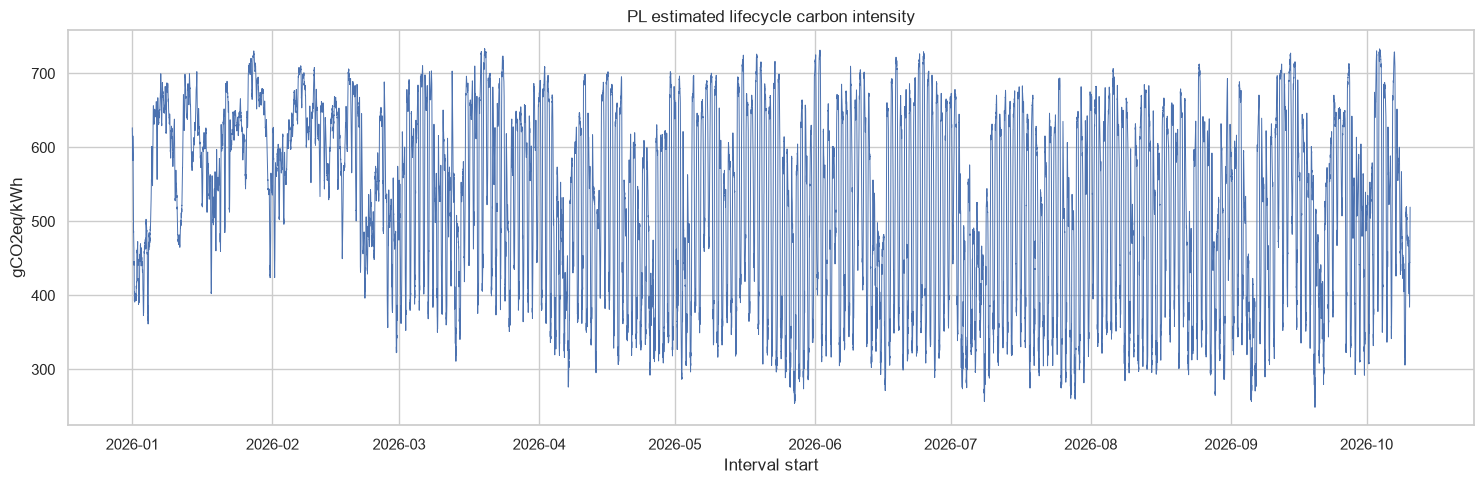

In [11]:
plot_data = interval_summary.dropna(subset=["Interval start", "Estimated carbon intensity (gCO2eq/kWh)"]).sort_values("Interval start")

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    plot_data["Interval start"],
    plot_data["Estimated carbon intensity (gCO2eq/kWh)"],
    linewidth=0.7
)
ax.set_title("PL estimated lifecycle carbon intensity")
ax.set_xlabel("Interval start")
ax.set_ylabel("gCO2eq/kWh")
fig.tight_layout()
plt.show()

## 12. Daily and monthly summaries

In [12]:
time_data = interval_summary.dropna(subset=["Interval start"]).copy()
time_data["Date"] = time_data["Interval start"].dt.date
time_data["Month"] = time_data["Interval start"].dt.to_period("M").astype(str)

daily_summary = (
    time_data.groupby("Date")
    .agg(
        mean_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "mean"),
        min_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "min"),
        max_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "max"),
        total_generation_MWh=("Total generation included (MW)", lambda s: s.sum() * INTERVAL_HOURS),
        total_emissions_tCO2eq=("Estimated total emissions (tCO2eq per 15 min)", "sum")
    )
    .reset_index()
)
monthly_summary = (
    time_data.groupby("Month")
    .agg(
        mean_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "mean"),
        min_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "min"),
        max_carbon_intensity_gCO2eq_kWh=("Estimated carbon intensity (gCO2eq/kWh)", "max"),
        total_generation_MWh=("Total generation included (MW)", lambda s: s.sum() * INTERVAL_HOURS),
        total_emissions_tCO2eq=("Estimated total emissions (tCO2eq per 15 min)", "sum")
    )
    .reset_index()
)

display(daily_summary.head())
display(monthly_summary)

,Date,mean_carbon_intensity_gCO2eq_kWh,min_carbon_intensity_gCO2eq_kWh,max_carbon_intensity_gCO2eq_kWh,total_generation_MWh,total_emissions_tCO2eq
0,2026-01-01,458.896782,390.980327,626.588531,433714.8025,195356.171875
1,2026-01-02,437.506506,387.710178,472.692973,463528.0475,202254.409425
2,2026-01-03,438.275578,372.651473,477.466160,464487.52,202847.313093
3,2026-01-04,455.020196,361.322594,502.853807,462099.455,208946.937645
4,2026-01-05,587.962284,490.328480,656.460061,475839.96,280815.663732


,Month,mean_carbon_intensity_gCO2eq_kWh,min_carbon_intensity_gCO2eq_kWh,max_carbon_intensity_gCO2eq_kWh,total_generation_MWh,total_emissions_tCO2eq
0,2026-01,589.808208,361.322594,730.466191,16088574.2025,9514490.003423
1,2026-02,585.448696,322.526285,710.349777,13900868.01,8117526.270822
2,2026-03,555.106496,310.963040,733.848886,14510618.4725,7964562.758505
3,2026-04,503.202777,276.046702,709.215077,13750025.9225,6783677.279962
4,2026-05,514.529105,254.183261,726.176481,13111448.545,6537117.291932
5,2026-06,521.811780,271.305155,731.556965,12858368.425,6526230.636088
6,2026-07,483.908591,256.731323,693.861870,13084261.24,6159086.30423
7,2026-08,508.892223,264.854918,712.762007,13240487.7875,6550449.092403
8,2026-09,509.304614,248.686677,727.505238,13003770.225,6479055.94456
9,2026-10,531.537300,305.765935,733.204398,4393712.8875,2279863.415977


## 13. Save interval-level summary tables (optional)

In [13]:
INTERVAL_SUMMARY_CSV = OUTPUT_CSV.with_name(OUTPUT_CSV.stem + "_interval_summary.csv")
DAILY_SUMMARY_CSV = OUTPUT_CSV.with_name(OUTPUT_CSV.stem + "_daily_summary.csv")
MONTHLY_SUMMARY_CSV = OUTPUT_CSV.with_name(OUTPUT_CSV.stem + "_monthly_summary.csv")

interval_summary.to_csv(INTERVAL_SUMMARY_CSV, index=False)
daily_summary.to_csv(DAILY_SUMMARY_CSV, index=False)
monthly_summary.to_csv(MONTHLY_SUMMARY_CSV, index=False)

print("Saved:")
print(INTERVAL_SUMMARY_CSV.resolve())
print(DAILY_SUMMARY_CSV.resolve())
print(MONTHLY_SUMMARY_CSV.resolve())

Saved:
C:\University25\master\_teza_master\soft\project\data\PL_generation_with_estimated_carbon_intensity_interval_summary.csv
C:\University25\master\_teza_master\soft\project\data\PL_generation_with_estimated_carbon_intensity_daily_summary.csv
C:\University25\master\_teza_master\soft\project\data\PL_generation_with_estimated_carbon_intensity_monthly_summary.csv


## Interpretation and limitations

- This is a **generation-weighted lifecycle estimate** based on assigned factors. It is not an official ENTSO-E carbon-intensity field.
- The calculation assumes `Generation (MW)` represents average power over each 15-minute interval.
- Missing generation observations are not imputed as zero. They are omitted from the relevant sums; therefore, intervals with substantial missing data may be biased.
- Storage and pumped storage are excluded. A more complete storage model would attribute charging emissions to discharged energy, accounting for round-trip efficiency and charging time.
- The proxy factors for `Other`, `Other renewable`, `Geothermal`, `Marine`, `Waste`, and some fossil categories are coarse assumptions. For thesis-grade results, document each factor's source and conduct sensitivity analysis.
- Average lifecycle intensity is not marginal carbon intensity. Workload-shifting claims should not interpret changes in this estimate as exact avoided emissions without a marginal-emissions model.